# Supermarket Sales — Exploratory Analysis

**Assignment 1, Part 2.** Three months (Jan–Mar 2019) of transactions from a three-branch supermarket chain in Myanmar. One row per invoice, 1,000 invoices in total.

I ask three business questions: **who** the loyalty program pays off for, **where** each branch under-sells a product line, and **what lever** (volume or price) grows the basket. For each: the question, who would act on the answer, what I found as a ratio, and whether a chart earned its place.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

# colourblind-safe categorical palette (slots 1-3)
CAT = ["#2a78d6", "#eb6834", "#1baf7a"]
BLUE = "#2a78d6"

df = pd.read_csv("supermarket_sales.csv")
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


## Question 1 — Does the loyalty program actually pay for itself?

**The question:** Do loyalty Members spend more per basket than Normal customers, and by how much — and where does that advantage disappear?

**Why I asked it, and who acts on it.** A loyalty program only earns its keep if members buy more. The **head of CRM / loyalty** would use this to decide whether to keep funding member acquisition, and whether the program needs reworking at branches where it adds nothing.

**What I found.** Members spend only **3% more per basket** overall (327.79 vs 318.12 MMK), and the premium is uneven:

- **Branch A** — +5.7%
- **Branch B** — +3.5%
- **Branch C** — −0.3% (essentially zero)

The loyalty program is a weak lever overall, and at Branch C it isn't buying any extra spend at all.

In [2]:
g = df.groupby("Customer type")["Total"].agg(n="size", revenue="sum", avg="mean")

premium = (g.loc["Member", "avg"] / g.loc["Normal", "avg"] - 1) * 100
print("Overall member premium on average basket:", round(premium, 1), "%")
print()

branch_type = df.pivot_table(index="Branch", columns="Customer type", values="Total", aggfunc="mean")
branch_type["member_premium_pct"] = (branch_type["Member"] / branch_type["Normal"] - 1) * 100
branch_type.round(1)

Overall member premium on average basket: 3.0 %



Customer type,Member,Normal,member_premium_pct
Branch,,,
A,321.2,303.8,5.7
B,325.5,314.3,3.5
C,336.6,337.7,-0.3


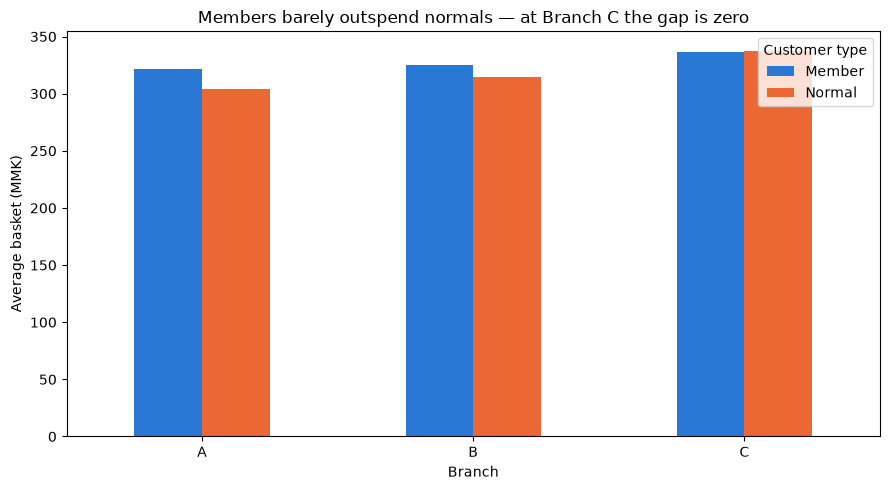

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
branch_type[["Member", "Normal"]].plot(kind="bar", ax=ax, color=CAT[:2])
ax.set_title("Members barely outspend normals — at Branch C the gap is zero")
ax.set_xlabel("Branch")
ax.set_ylabel("Average basket (MMK)")
ax.legend(title="Customer type")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

**Chart — worth its place.** The grouped bars show the premium *shrinking* from A to C — a visible gap at A collapsing to nothing at C — which a single overall 3% figure would hide. (The pivot table is kept because the exact per-branch premium is what the loyalty team would act on.)

## Question 2 — Which branch under-sells which product line?

**The question:** Which product line does each branch sell materially less of than its peer branches?

**Why I asked it, and who acts on it.** A branch that under-sells one line by a third most likely has a local problem — shelf space, stocking, staff training, or local demand — not a chain-wide category problem. The **regional category manager** would use this to decide where to send a category review, and each **store manager** would use it to see their own blind spot.

**What I found.** Each branch has a *different* weak line, and the gap is large enough to matter:

- **Branch A** under-sells **Health & beauty** — 37% below Branch B (12,598 vs 19,981).
- **Branch B** under-sells **Food & beverages** — 36% below Branch C (15,215 vs 23,767).
- **Branch C** under-sells **Home & lifestyle** — 38% below Branch A (13,896 vs 22,417).

Because the weak line differs at every branch, the fix is branch-specific, not a company-wide push.

In [4]:
pv = df.pivot_table(index="Product line", columns="Branch", values="Total", aggfunc="sum")
pv.round(0)

Branch,A,B,C
Product line,,,
Electronic accessories,18317.0,17051.0,18969.0
Fashion accessories,16333.0,16413.0,21560.0
Food and beverages,17163.0,15215.0,23767.0
Health and beauty,12598.0,19981.0,16615.0
Home and lifestyle,22417.0,17549.0,13896.0
Sports and travel,19373.0,19988.0,15762.0


In [5]:
# each branch's weakest line, and how far it trails the best branch for that same line
weak_line = pv.idxmin()
weak_val = pv.min()
best_val = pd.Series([pv.loc[weak_line[b], :].max() for b in pv.columns], index=pv.columns)

gap = pd.DataFrame({
    "Branch": pv.columns,
    "weakest_line": weak_line.values,
    "revenue": weak_val.values,
    "best_branch_for_line": best_val.values,
})
gap["gap_pct"] = (gap["best_branch_for_line"] - gap["revenue"]) / gap["best_branch_for_line"] * 100
gap.round(1)

,Branch,weakest_line,revenue,best_branch_for_line,gap_pct
0,A,Health and beauty,12597.8,19980.7,37.0
1,B,Food and beverages,15214.9,23766.9,36.0
2,C,Home and lifestyle,13895.6,22417.2,38.0


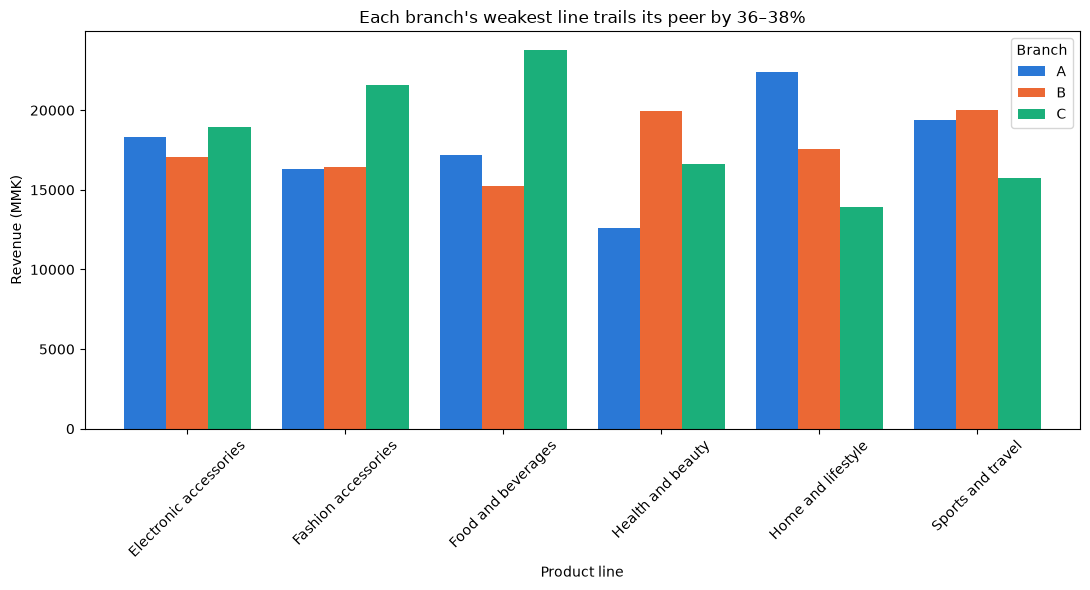

In [6]:
fig, ax = plt.subplots(figsize=(11, 6))
pv.plot(kind="bar", ax=ax, color=CAT, width=0.8)
ax.set_title("Each branch's weakest line trails its peer by 36–38%")
ax.set_xlabel("Product line")
ax.set_ylabel("Revenue (MMK)")
ax.tick_params(axis="x", rotation=45)
ax.legend(title="Branch")
plt.tight_layout()
plt.show()

**Chart — worth its place.** The grouped bar chart shows the whole 6×3 matrix at once, and the short bar appearing at a *different position for each branch* is exactly what the table of three gap numbers cannot show: that the weakness is localised, not systematic. (The pivot table is kept because the exact figures back the three headline gaps.)

## Question 3 — Grow by "buy one more", or by "buy the pricier one"?

**The question:** Does a bigger basket come from customers buying *more items*, or buying *pricier items*?

**Why I asked it, and who acts on it.** The chain can grow basket size two ways — push volume (multi-buy, bundles) or push premium (upgrade to a higher-priced item) — and they need different promotions, shelf layouts and staff scripts. The **head of merchandising / purchasing** would use this to decide where to put next quarter's trade budget.

**What I found.** Quantity is the bigger driver. Taking logs splits a basket cleanly into log(basket) = log(items) + log(unit price); then the number of items tracks basket size much more tightly than unit price does (**correlation 0.77 vs 0.64**), and it also swings more (**spread 0.71 vs 0.59**). In plain words: a big basket is mostly someone buying *more items*, not someone buying *more expensive items*.

In [7]:
log_q = np.log(df["Quantity"])
log_p = np.log(df["Unit price"])
log_t = np.log(df["Total"])

driver = pd.DataFrame({
    "correlation_with_basket": [log_q.corr(log_t), log_p.corr(log_t)],
    "spread (log std)": [log_q.std(), log_p.std()],
}, index=["Quantity (how many items)", "Unit price (how pricey)"])
driver.round(3)

,correlation_with_basket,spread (log std)
Quantity (how many items),0.771,0.712
Unit price (how pricey),0.640,0.590


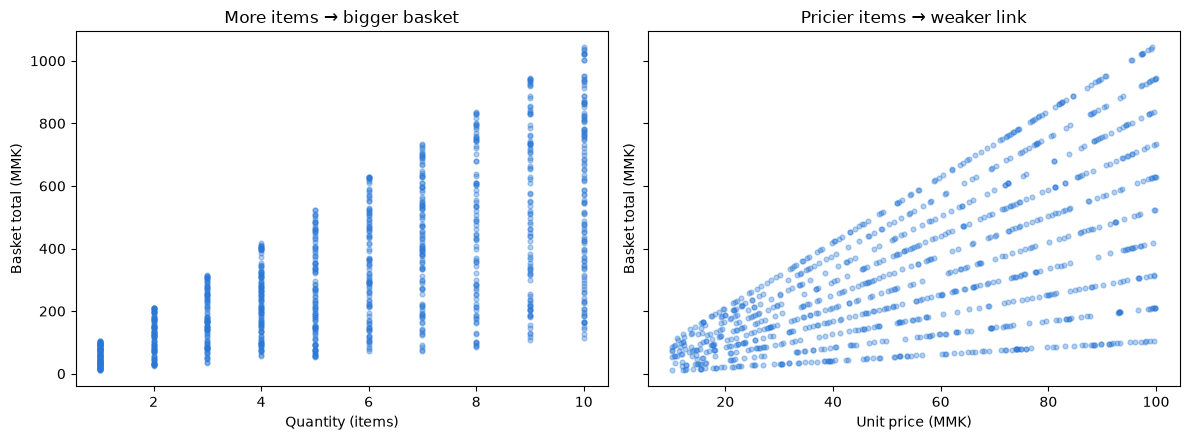

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
axes[0].scatter(df["Quantity"], df["Total"], s=12, alpha=0.35, color=BLUE)
axes[0].set_title("More items → bigger basket")
axes[0].set_xlabel("Quantity (items)")
axes[0].set_ylabel("Basket total (MMK)")
axes[1].scatter(df["Unit price"], df["Total"], s=12, alpha=0.35, color=BLUE)
axes[1].set_title("Pricier items → weaker link")
axes[1].set_xlabel("Unit price (MMK)")
axes[1].set_ylabel("Basket total (MMK)")
plt.tight_layout()
plt.show()

**Chart — worth its place.** The two scatter plots make the finding visible: the left panel (items vs basket) is a clean rising band, while the right panel (price vs basket) is a much looser cloud. The correlations say it; the chart makes it obvious at a glance. (The table is kept because the two correlations are the number a decision needs.)

## Which finding is most worth the company's time?

**The membership result (Question 1).** The other two are real but bounded — one weak product line at each branch, or a choice of promotion tactics. The membership finding questions an *entire ongoing budget line*: if being a Member only adds 3% to the basket, and nothing at all in Branch C, the company may be funding a loyalty program that isn't changing behaviour. That is a chain-wide decision with a much bigger price tag than any single category gap, so it is the one to dig into first.